In [ ]:
!pip install gradio -q

In [ ]:
import os
import gzip
import shutil
import urllib.request
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import gradio as gr

In [ ]:
TRACE_URL = "https://storage.googleapis.com/clusterdata-2011-2/task_events/part-00000-of-00500.csv.gz"
LOCAL_GZ = "task_events_sample.csv.gz"
LOCAL_CSV = "task_events_sample.csv"

if not os.path.exists(LOCAL_CSV):
    print("Downloading a real shard of the Google Cluster Trace (task_events)...")
    urllib.request.urlretrieve(TRACE_URL, LOCAL_GZ)
    with gzip.open(LOCAL_GZ, 'rb') as f_in, open(LOCAL_CSV, 'wb') as f_out:
        shutil.copyfileobj(f_in, f_out)
    print("Download + extraction complete.")
else:
    print("File already exists locally.")

Download + extraction complete.


In [ ]:
column_names = [
    "timestamp", "missing_info", "job_id", "task_index", "machine_id",
    "event_type", "user", "scheduling_class", "priority",
    "cpu_request", "memory_request", "disk_space_request",
    "different_machine_constraint"
]

df = pd.read_csv(LOCAL_CSV, header=None, names=column_names, nrows=200_000)
print(f"Loaded {len(df)} raw task events")
df.head()

Loaded 200000 raw task events


,timestamp,missing_info,job_id,task_index,machine_id,event_type,user,scheduling_class,priority,cpu_request,memory_request,disk_space_request,different_machine_constraint
0,0,2.0,3418309,0,4.155527e+09,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,9,NaN,NaN,NaN,NaN
1,0,2.0,3418309,1,3.291507e+08,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,9,NaN,NaN,NaN,NaN
2,0,NaN,3418314,0,3.938719e+09,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,9,0.125,0.07446,0.000424,0.0
3,0,NaN,3418314,1,3.516186e+08,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,9,0.125,0.07446,0.000424,0.0
4,0,2.0,3418319,0,4.310529e+08,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,9,NaN,NaN,NaN,NaN


In [ ]:
# Keep only SUBMIT events (event_type == 0) -> these represent new tasks arriving
submits = df[df["event_type"] == 0].copy()
submits = submits.dropna(subset=["priority", "cpu_request", "memory_request"])
submits = submits.sort_values("timestamp").reset_index(drop=True)

# Bucket priority into High/Low (Google's "production" priorities are 9-11)
submits["priority_level"] = submits["priority"].apply(lambda p: 1 if p >= 9 else 0)

# Bucket CPU request into Short/Long task duration proxy
median_cpu = submits["cpu_request"].median()
submits["duration_level"] = submits["cpu_request"].apply(lambda c: 2 if c >= median_cpu else 1)

task_stream = submits[["priority_level", "duration_level"]].reset_index(drop=True)
print(f"Usable task stream: {len(task_stream)} real tasks")
print(task_stream["priority_level"].value_counts(normalize=True))

Usable task stream: 144048 real tasks
priority_level
0    0.611574
1    0.388426
Name: proportion, dtype: float64


In [ ]:
class TaskSchedulingEnv:
    """
    Same scheduling logic as before, but now task arrivals are pulled
    from the real Google Cluster Trace instead of being randomly generated.
    """
    def __init__(self, task_stream, num_servers=2, max_load=2, tasks_per_episode=20):
        self.task_stream = task_stream
        self.num_servers = num_servers
        self.max_load = max_load
        self.tasks_per_episode = tasks_per_episode
        self.action_size = num_servers + 1
        self.reset()

    def reset(self):
        self.server_load = [0] * self.num_servers
        self.step_count = 0
        self.pointer = random.randint(0, len(self.task_stream) - self.tasks_per_episode - 1)
        self._load_task()
        return self._get_state()

    def _load_task(self):
        row = self.task_stream.iloc[self.pointer]
        self.task_priority = int(row["priority_level"])
        self.task_duration = int(row["duration_level"])
        self.pointer += 1

    def _get_state(self):
        return tuple(self.server_load) + (self.task_priority,)

    def step(self, action):
        reward = 0
        info = {}

        if action < self.num_servers:
            server = action
            if self.server_load[server] == 0:
                reward = 10 if self.task_priority == 1 else 5
                self.server_load[server] = min(self.max_load, self.task_duration)
                info["result"] = f"Assigned to Server {server+1} (free)"
            else:
                reward = -10 if self.task_priority == 1 else -5
                self.server_load[server] = min(self.max_load, self.server_load[server] + 1)
                info["result"] = f"Assigned to Server {server+1} (busy — delayed)"
        else:
            if any(l == 0 for l in self.server_load):
                reward = -8 if self.task_priority == 1 else -3
                info["result"] = "Waited (a server was free — bad choice)"
            else:
                reward = 2
                info["result"] = "Waited (all servers busy — good choice)"

        self.server_load = [max(0, l - 1) for l in self.server_load]
        self.step_count += 1
        done = self.step_count >= self.tasks_per_episode

        prev_priority, prev_duration = self.task_priority, self.task_duration
        if not done:
            self._load_task()

        info["priority"] = "High" if prev_priority == 1 else "Low"
        info["duration"] = "Long" if prev_duration == 2 else "Short"
        info["reward"] = reward
        return self._get_state(), reward, done, info

In [ ]:
class SARSAAgent:
    def __init__(self, action_size, alpha=0.1, gamma=0.9, epsilon=0.3):
        self.q_table = {}
        self.action_size = action_size
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon

    def get_q(self, state, action):
        return self.q_table.get((state, action), 0.0)

    def choose_action(self, state, greedy=False):
        if not greedy and random.random() < self.epsilon:
            return random.randint(0, self.action_size - 1)
        q_values = [self.get_q(state, a) for a in range(self.action_size)]
        max_q = max(q_values)
        best = [a for a, q in enumerate(q_values) if q == max_q]
        return random.choice(best)

    def update(self, s, a, r, s_next, a_next):
        current_q = self.get_q(s, a)
        next_q = self.get_q(s_next, a_next)
        self.q_table[(s, a)] = current_q + self.alpha * (r + self.gamma * next_q - current_q)

    def decay_epsilon(self, decay_rate=0.995, min_epsilon=0.02):
        self.epsilon = max(min_epsilon, self.epsilon * decay_rate)

In [ ]:
def train_sarsa(task_stream, episodes=3000, num_servers=2):
    env = TaskSchedulingEnv(task_stream, num_servers=num_servers)
    agent = SARSAAgent(action_size=env.action_size)
    episode_rewards = []

    for ep in range(episodes):
        state = env.reset()
        action = agent.choose_action(state)
        total_reward = 0
        done = False

        while not done:
            next_state, reward, done, _ = env.step(action)
            next_action = agent.choose_action(next_state)
            agent.update(state, action, reward, next_state, next_action)
            state, action = next_state, next_action
            total_reward += reward

        agent.decay_epsilon()
        episode_rewards.append(total_reward)

    return agent, env, episode_rewards

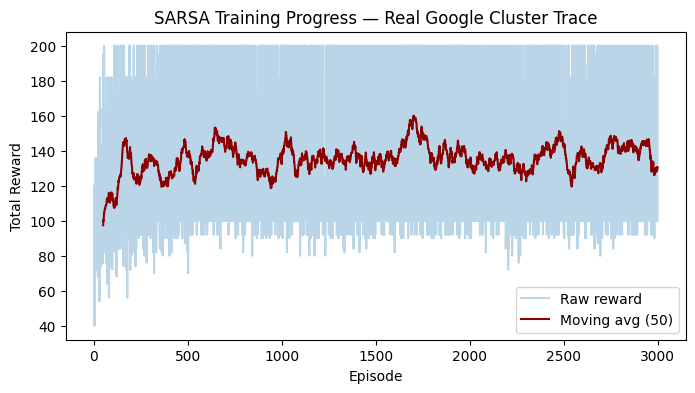

Q-table size: 18 state-action pairs learned


In [ ]:
NUM_SERVERS = 2
trained_agent, env_template, episode_rewards = train_sarsa(task_stream, episodes=3000, num_servers=NUM_SERVERS)

plt.figure(figsize=(8, 4))
smoothed = pd.Series(episode_rewards).rolling(50).mean()
plt.plot(episode_rewards, alpha=0.3, label="Raw reward")
plt.plot(smoothed, color="darkred", label="Moving avg (50)")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("SARSA Training Progress — Real Google Cluster Trace")
plt.legend()
plt.show()

print(f"Q-table size: {len(trained_agent.q_table)} state-action pairs learned")

In [ ]:
def run_policy(policy_fn, task_stream, num_tasks=15, num_servers=2, seed=None):
    if seed is not None:
        random.seed(seed)
    env = TaskSchedulingEnv(task_stream, num_servers=num_servers, tasks_per_episode=num_tasks)
    state = env.reset()
    log = []
    total_reward = 0
    rr_pointer = [0]

    for t in range(num_tasks):
        action = policy_fn(state, env, rr_pointer)
        next_state, reward, done, info = env.step(action)
        log.append({
            "Task #": t + 1, "Priority": info["priority"], "Duration": info["duration"],
            "Decision": info["result"], "Reward": info["reward"]
        })
        total_reward += reward
        state = next_state
        if done:
            break

    return pd.DataFrame(log), total_reward

def sarsa_policy(state, env, rr_pointer):
    return trained_agent.choose_action(state, greedy=True)

def round_robin_policy(state, env, rr_pointer):
    server = rr_pointer[0] % env.num_servers
    rr_pointer[0] += 1
    return server

def random_policy(state, env, rr_pointer):
    return random.randint(0, env.action_size - 1)

In [ ]:
def simulate_and_compare(num_tasks, seed):
    seed = int(seed)
    sarsa_log, sarsa_total = run_policy(sarsa_policy, task_stream, num_tasks, NUM_SERVERS, seed)
    rr_log, rr_total = run_policy(round_robin_policy, task_stream, num_tasks, NUM_SERVERS, seed)
    rand_log, rand_total = run_policy(random_policy, task_stream, num_tasks, NUM_SERVERS, seed)

    fig, ax = plt.subplots(figsize=(6, 4))
    methods = ["SARSA (RL)", "Round Robin", "Random"]
    totals = [sarsa_total, rr_total, rand_total]
    colors = ["#2E7D32", "#1976D2", "#B0BEC5"]
    bars = ax.bar(methods, totals, color=colors)
    ax.set_ylabel("Total Reward")
    ax.set_title(f"Scheduling Performance on Real Google Trace Data ({num_tasks} tasks)")
    for bar, val in zip(bars, totals):
        ax.text(bar.get_x() + bar.get_width()/2, val, str(val), ha="center", va="bottom" if val >= 0 else "top")
    plt.tight_layout()

    summary = (
        f"**SARSA total reward:** {sarsa_total}\n\n"
        f"**Round Robin total reward:** {rr_total}\n\n"
        f"**Random total reward:** {rand_total}\n\n"
        f"**SARSA improvement over Round Robin:** {sarsa_total - rr_total:+d} points"
    )
    return sarsa_log, summary, fig

with gr.Blocks(title="SARSA Scheduler — Google Cluster Trace") as demo:
    gr.Markdown("# 🧠 Dynamic Task Scheduling — SARSA on Real Google Cluster Trace Data")
    gr.Markdown("Trained on real task submission logs from Google's production datacenter (May 2011 trace).")

    with gr.Row():
        num_tasks_slider = gr.Slider(5, 50, value=15, step=1, label="Number of Tasks to Simulate")
        seed_input = gr.Number(value=42, label="Random Seed")

    run_btn = gr.Button("▶ Run Simulation", variant="primary")

    with gr.Row():
        with gr.Column():
            output_table = gr.Dataframe(label="SARSA Agent — Step-by-Step Decisions")
        with gr.Column():
            output_summary = gr.Markdown()
            output_plot = gr.Plot(label="Reward Comparison")

    run_btn.click(fn=simulate_and_compare, inputs=[num_tasks_slider, seed_input],
                  outputs=[output_table, output_summary, output_plot])

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://4da4afb3b1e8631fcc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
